# 12. 2D Nanostructure Near-Field Visualization (In-Plane and Cross-Sections)

## Physical Motivation & Learning Objectives
Full 3D electromagnetic near-fields contain rich spatial information. In this tutorial:
1. We compute 2D modes with `plotting_fields=True`.
2. We extract in-plane $(x, y)$ field maps using `plotting.fields_interpolator_in_plane`.
3. We extract fast vertical $(x, z)$ cross-sections across the entire stack using `plotting.fields_interpolator_cross_section`.

> [!NOTE]
> **Meshing Workflow: Classic Gmsh (`examples/`)**
> Uses classic Gmsh meshing via `make_mesh_now=True`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack


## Silicon Nanowire Stack Setup


In [2]:
wl = 615.0            # nm
period = 600.0        # nm
NW_diameter = 200.0   # nm

light = objects.Light(wl, max_order_PWs=1, theta=0.0, phi=0.0)

superstrate = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Air, loss=False)
spacer      = objects.ThinFilm(period, height_nm=150.0, material=materials.SiO2, loss=True)
substrate   = objects.ThinFilm(period, height_nm='semi_inf', material=materials.Material(1.45), loss=False)

NW_array = objects.NanoStruct(
    '2D_array', period, NW_diameter,
    height_nm=600.0,
    inclusion_a=materials.Si_c,
    background=materials.Air,
    loss=True,
    make_mesh_now=True, lc_bkg=0.1, lc2=2.0,
    plotting_fields=True,
    plt_msh=False
)

sim_sup = superstrate.calc_modes(light)
sim_nw  = NW_array.calc_modes(light, num_BMs=14)
sim_spc = spacer.calc_modes(light)
sim_sub = substrate.calc_modes(light)

stk = Stack((sim_sub, sim_spc, sim_nw, sim_sup))
stk.calc_scat(pol='TE')


## In-Plane $(x, y)$ Local Field Intensity Maps


<ipython-input-1-9ea63a22aba8>:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


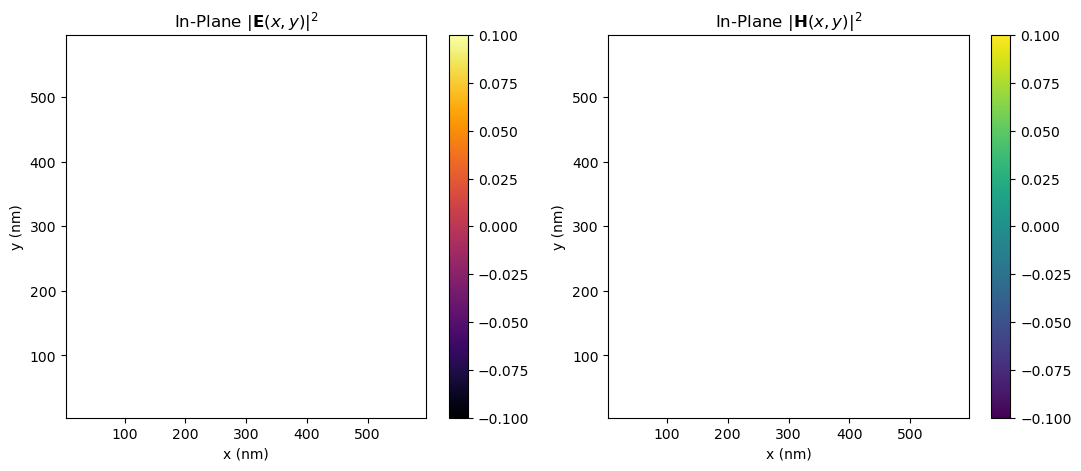

In [3]:
bundle_xy = plotting.fields_interpolator_in_plane(stk, lay_interest=2, z_value=300.0, return_H=True)

grid_n = 120
xg = np.linspace(0.01, 0.99, grid_n) * period
yg = np.linspace(0.01, 0.99, grid_n) * period
X, Y = np.meshgrid(xg, yg)

E_norm2 = bundle_xy.AbsE(X, Y)**2
H_norm2 = bundle_xy.AbsH(X, Y)**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8), dpi=110)
im1 = ax1.pcolormesh(X, Y, E_norm2, cmap='inferno', shading='auto')
ax1.set_title(r'In-Plane $|\mathbf{E}(x, y)|^2$', fontsize=12)
ax1.set_xlabel('x (nm)')
ax1.set_ylabel('y (nm)')
plt.colorbar(im1, ax=ax1)

im2 = ax2.pcolormesh(X, Y, H_norm2, cmap='viridis', shading='auto')
ax2.set_title(r'In-Plane $|\mathbf{H}(x, y)|^2$', fontsize=12)
ax2.set_xlabel('x (nm)')
ax2.set_ylabel('y (nm)')
plt.colorbar(im2, ax=ax2)

# Overlay circular boundary
theta = np.linspace(0, 2*np.pi, 100)
xc = period / 2.0 + (NW_diameter / 2.0) * np.cos(theta)
yc = period / 2.0 + (NW_diameter / 2.0) * np.sin(theta)
ax1.plot(xc, yc, 'w--', lw=1.2)
ax2.plot(xc, yc, 'w--', lw=1.2)

plt.tight_layout()
plt.show()


## Vertical $(x, z)$ Full-Stack Cross-Section


<ipython-input-1-828c820eb99f>:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


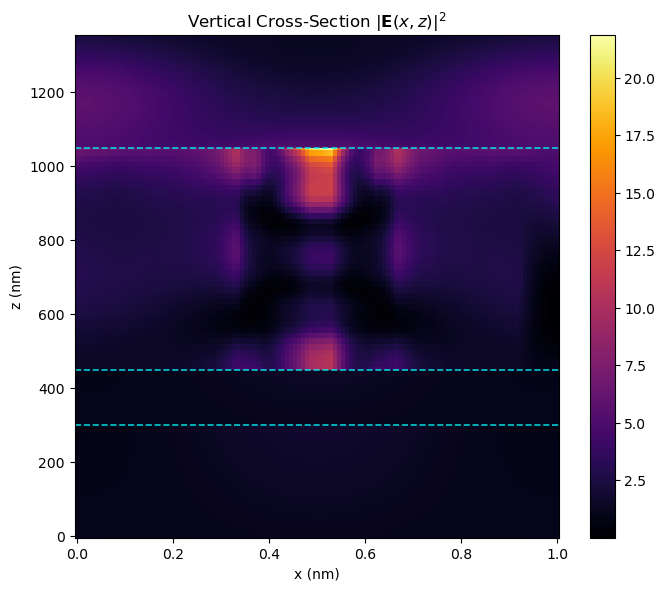

In [4]:
bundle_xz = plotting.fields_interpolator_cross_section(
    stk, plane='xz', slice_coord=0.5, n_horiz=120, n_vert_per_layer=40, return_H=True
)

X_xz, Z_xz = np.meshgrid(bundle_xz.u_grid, bundle_xz.v_grid, indexing='ij')
E_xz = bundle_xz.AbsE(X_xz, Z_xz)**2

fig, ax = plt.subplots(figsize=(7, 6), dpi=110)
im = ax.pcolormesh(X_xz, Z_xz, E_xz, cmap='inferno', shading='auto')
for z_if in bundle_xz.interface_z_nm:
    ax.axhline(z_if, color='cyan', linestyle='--', lw=1.2, alpha=0.8)
ax.set_title(r'Vertical Cross-Section $|\mathbf{E}(x, z)|^2$', fontsize=12)
ax.set_xlabel('x (nm)')
ax.set_ylabel('z (nm)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


## Physical Interpretation
- Inside the silicon pillar, the electric field forms a strongly localized cylindrical cavity resonance with tight energy confinement.
- Across the $(x, z)$ vertical section, field amplitude decays rapidly into the air superstrate above the pillar.
